<a href="https://colab.research.google.com/github/JOJO-REWADIA/Capstone-Project-2-Amazon-Prime-TV-Shows-and-Movies/blob/main/Capstone_project_2_Amazon_Prime_TV_Shows_and_Movies.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## NAME - HIMANSHU

## STUDENT ID - AB-9033-4995-97

## Email - hrewadia4@gmail.com


## GITHUB LINK

# Capstone Project 2: Amazon Prime TV Shows and Movies

## Business Context
In today's competitive streaming industry, platforms like Amazon Prime Video are constantly expanding their content libraries to cater to diverse audiences. Data-driven insights play a crucial role in understanding trends, audience preferences, and content strategy.

## Problem Statement
The objective of this project is to analyze the Amazon Prime dataset to extract valuable insights regarding:
1. **Content Diversity**: What genres and categories dominate the platform?
2. **Regional Availability**: How does content distribution vary across different regions?
3. **Trends Over Time**: How has Amazon Prime’s content library evolved?
4. **Ratings & Popularity**: What are the highest-rated or most popular shows/movies?

## Hypotheses/Assumptions
1. Movies significantly outnumber TV shows on Amazon Prime.
2. The United States and India are the top production countries for the platform.
3. Drama and Comedy are the most prevalent genres.
4. There has been an exponential growth in content added in the last decade (post-2010).

# **2. Data Loading and Cleanup**

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Set visual style
sns.set_theme(style="whitegrid")

# Load the datasets
titles_df = pd.read_csv('titles.csv')
credits_df = pd.read_csv('credits.csv')

# Data Understanding & Basic Info
print("Titles Dataset Shape:", titles_df.shape)
print("Credits Dataset Shape:", credits_df.shape)
titles_df.head()

Titles Dataset Shape: (9871, 15)
Credits Dataset Shape: (124235, 5)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


In [ ]:
import pandas as pd
import numpy as np
import ast

# Data Cleanup
# 1. Check for missing values
print(titles_df.isnull().sum())

# 2. Handle missing values
# For scores and votes, we can fill with the median to maintain distribution,
# or drop rows if we strictly need accurate rating analyses. Let's fill continuous with median.
titles_df['imdb_score'] = titles_df['imdb_score'].fillna(titles_df['imdb_score'].median())
titles_df['tmdb_score'] = titles_df['tmdb_score'].fillna(titles_df['tmdb_score'].median())

# For categorical columns like age_certification, fill with 'Not Rated'
titles_df['age_certification'] = titles_df['age_certification'].fillna('Not Rated')

# 3. Clean 'genres' and 'production_countries' (they are strings of lists)
def clean_list_column(text):
    try:
        # Evaluate the string representation of list to an actual list
        return ast.literal_eval(text)
    except:
        return []

titles_df['genres'] = titles_df['genres'].apply(clean_list_column)
titles_df['production_countries'] = titles_df['production_countries'].apply(clean_list_column)

# Convert list columns to tuples for hashing before dropping duplicates
titles_df['genres'] = titles_df['genres'].apply(tuple)
titles_df['production_countries'] = titles_df['production_countries'].apply(tuple)

# 4. Check for duplicates
titles_df.drop_duplicates(inplace=True)

# Convert back to list if needed for later operations
titles_df['genres'] = titles_df['genres'].apply(list)
titles_df['production_countries'] = titles_df['production_countries'].apply(list)

id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64


# **3. Exploratory Data Analysis & Visualizations (At least 5)**

# Visualization 1: Movies vs. TV Shows (Univariate)
Code Cell

/tmp/ipykernel_1415/3787565041.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=titles_df, x='type', palette='Set2')


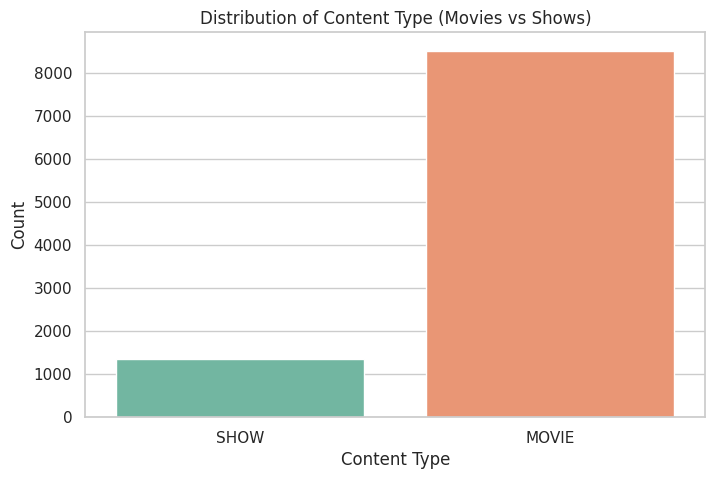

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=titles_df, x='type', palette='Set2')
plt.title('Distribution of Content Type (Movies vs Shows)')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

Remarks: This plot confirms our hypothesis that movies heavily dominate the Amazon Prime library compared to TV shows.

# Visualization 2: Content Release Trends Over Time (Bivariate)
Code Cell:

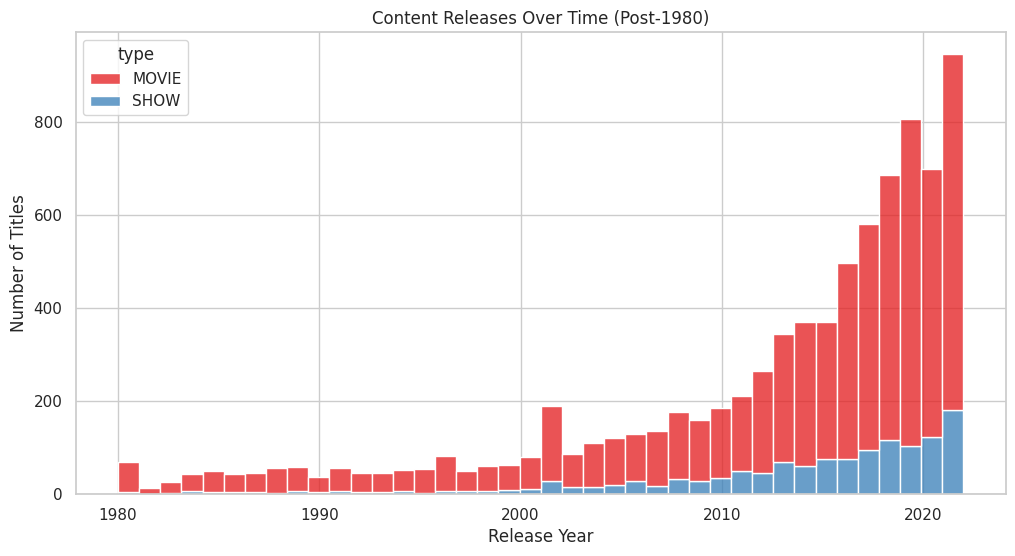

In [ ]:
plt.figure(figsize=(12, 6))
# Filter to content from 1980 onwards for better visibility
recent_titles = titles_df[titles_df['release_year'] >= 1980]
sns.histplot(data=recent_titles, x='release_year', hue='type', multiple='stack', bins=40, palette='Set1')
plt.title('Content Releases Over Time (Post-1980)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

Remarks: We observe an exponential spike in content availability released after 2010, reflecting the boom of the streaming era and Amazon's aggressive content acquisition strategy.


# Visualization 3: Top 10 Genres (Categorical)
Code Cell:

/tmp/ipykernel_1415/36659369.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=genre_counts.index, x=genre_counts.values, palette='viridis')


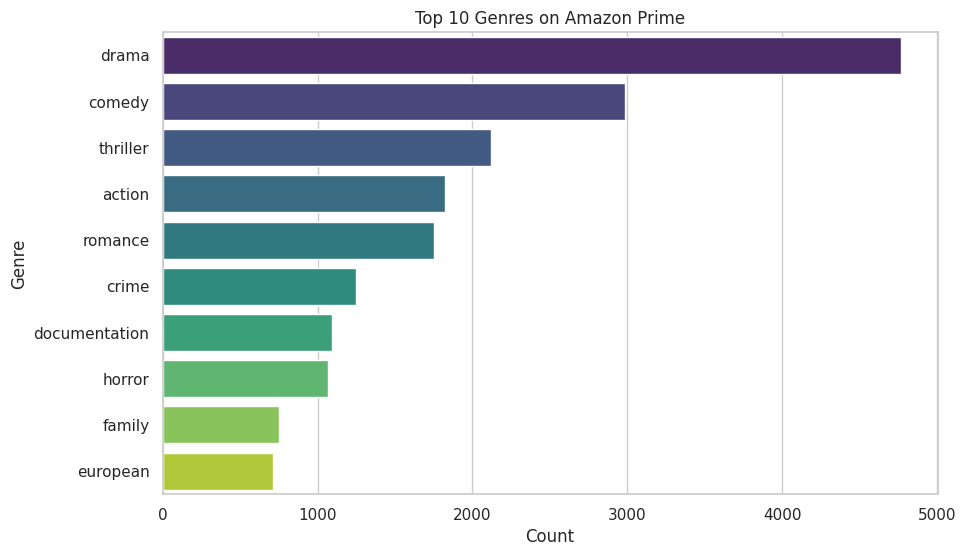

In [ ]:
# Explode the genres list to count individual genres
exploded_genres = titles_df.explode('genres')
genre_counts = exploded_genres['genres'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(y=genre_counts.index, x=genre_counts.values, palette='viridis')
plt.title('Top 10 Genres on Amazon Prime')
plt.xlabel('Count')
plt.ylabel('Genre')
plt.show()

Remarks: Drama and Comedy are clearly the most dominant genres, confirming our initial assumption. This suggests a mass-market content acquisition strategy.


# Visualization 4: Top Production Countries
Code Cell:

/tmp/ipykernel_1415/3472194230.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_counts.values, y=country_counts.index, palette='magma')


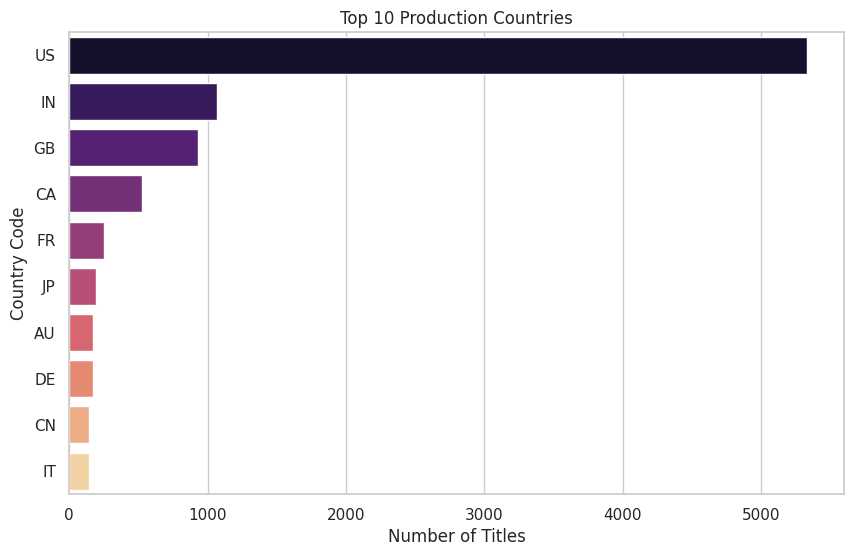

In [ ]:
exploded_countries = titles_df.explode('production_countries')
country_counts = exploded_countries['production_countries'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=country_counts.values, y=country_counts.index, palette='magma')
plt.title('Top 10 Production Countries')
plt.xlabel('Number of Titles')
plt.ylabel('Country Code')
plt.show()

Remarks: The US (United States) and IN (India) dominate the library, showcasing Amazon's heavy investment in Hollywood and Bollywood/Tollywood regional markets to drive subscription growth.


# Visualization 5: IMDb Score vs TMDB Score (Multivariate/Correlation)
Code Cell:

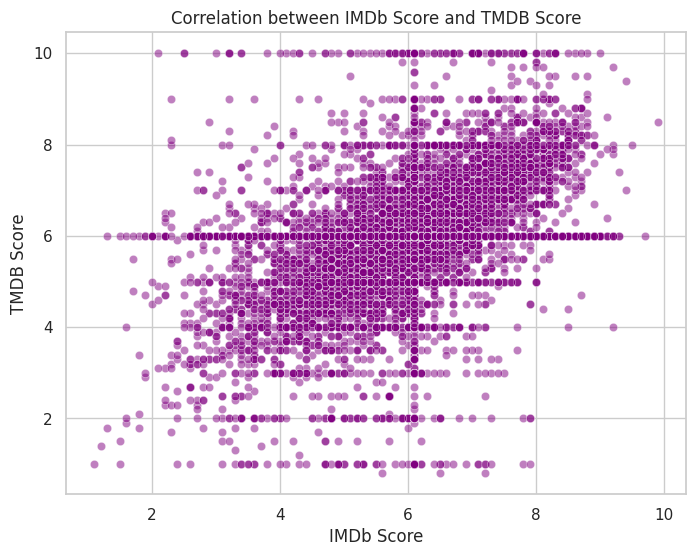

Pearson Correlation Coefficient: 0.49


In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=titles_df, x='imdb_score', y='tmdb_score', alpha=0.5, color='purple')
plt.title('Correlation between IMDb Score and TMDB Score')
plt.xlabel('IMDb Score')
plt.ylabel('TMDB Score')
plt.show()

# Statistical correlation
correlation = titles_df['imdb_score'].corr(titles_df['tmdb_score'])
print(f"Pearson Correlation Coefficient: {correlation:.2f}")

Remarks: There is a strong positive correlation between IMDb and TMDB scores, indicating that audience reception is generally consistent across different rating platforms.





# 4. Conclusion
Markdown Cell:


This analysis successfully mapped the content landscape of Amazon Prime Video.
1. **Content Strategy:** The platform relies heavily on feature-length Movies over TV Shows, leaning into Drama and Comedy genres to satisfy a broad audience base.
2. **Global Reach:** While US content anchors the platform, the massive volume of Indian content highlights Amazon's strategic push into one of the world's fastest-growing digital markets.
3. **Historical Trends:** A massive influx of modern content (post-2010) reveals the shift in the entertainment paradigm toward direct-to-streaming acquisitions.
Businesses and content creators can utilize these insights to understand that while niche genres have a place, broad-appeal dramas and comedies in major markets (US, India, UK) yield the highest volume of platform engagement.